# Page Rank



In [1]:
from pyspark import SparkConf, SparkContext

sc = SparkContext.getOrCreate(SparkConf())

In [2]:
def f(x):
    links=x[1][0]
    rank=x[1][1]
    n=len(links.split(","))
    result=[]
    for s in links.split(","):
        result.append((s,rank*1.0/n))
    return result

## Case 1：
pagerank0.txt

|page rank data|
|:---- |
|A:B |
|B:A |

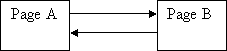

In [4]:
file="data/pagerank0.txt"

data=sc.textFile(file)
link=data.map(lambda x:(x.split(":")[0],x.split(":")[1]))
n=data.count()
print(n)
for l in link.collect():
    print(l)
rank=link.mapValues(lambda x:1.0)
for r in rank.collect():
    print(r)

for i in range(5):
    rank=link.join(rank).flatMap(f).reduceByKey(lambda x,y:x+y).mapValues(lambda x:0.15+0.85*x)
    
for r in rank.collect(): 
    print(r)   

2
('A', 'B')
('B', 'A')
('A', 1.0)
('B', 1.0)
('A', 1.0)
('B', 1.0)


## Case 2： 
pagerank1.txt

|page rank data|
|:---- |
|A:B,C,D |
|B:A,D |
|C:A |
|D:B,C |
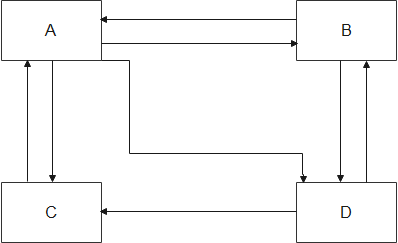

In [5]:
file="data/pagerank1.txt"

data=sc.textFile(file)
link=data.map(lambda x:(x.split(":")[0],x.split(":")[1]))
n=data.count()
print(n)
for l in link.collect():
    print(l)
rank=link.mapValues(lambda x:1.0)
for r in rank.collect():
    print(r)
    
for i in range(5):
    rank=link.join(rank).flatMap(f).reduceByKey(lambda x,y:x+y).mapValues(lambda x:0.15+0.85*x)
    
for r in rank.collect(): 
    print(r)   

4
('A', 'B,C,D')
('B', 'A,D')
('C', 'A')
('D', 'B,C')
('A', 1.0)
('B', 1.0)
('C', 1.0)
('D', 1.0)
('A', 1.3023810253906247)
('D', 0.8992063248697917)
('C', 0.8992063248697917)
('B', 0.8992063248697917)


## Case 3：
pagerank2.txt

|page rank data|
|:---- |
|A:B,C |
|B:C |
|C:A |
|D:C |
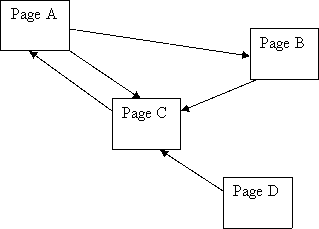

In [6]:
file="data/pagerank2.txt"

data=sc.textFile(file)
link=data.map(lambda x:(x.split(":")[0],x.split(":")[1]))
n=data.count()
print(n)
for l in link.collect():
    print(l)
rank=link.mapValues(lambda x:1.0)
for r in rank.collect():
    print(r)

for i in range(5):
    rank=link.join(rank).flatMap(f).reduceByKey(lambda x,y:x+y).mapValues(lambda x:0.15+0.85*x)
    
for r in rank.collect(): 
    print(r)   

4
('A', 'B,C')
('B', 'C')
('C', 'A')
('D', 'C')
('A', 1.0)
('B', 1.0)
('C', 1.0)
('D', 1.0)
('C', 1.2727444140624997)
('A', 1.4065417187499996)
('B', 0.7644191796874998)


## Case 4： 
pagerank3.txt

|page rank data|
|:---- |
|Home:About,Product,Links |
|About:Home |
|Product:Home |
|Links:Home, SiteA,SiteB, SiteC, SiteD |
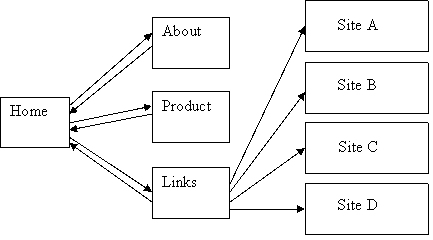

In [7]:
file="data/pagerank3.txt"

data=sc.textFile(file)
link=data.map(lambda x:(x.split(":")[0],x.split(":")[1]))
n=data.count()
print(n)
for l in link.collect():
    print(l)
rank=link.mapValues(lambda x:1.0)
for r in rank.collect():
    print(r)

for i in range(5):
    rank=link.join(rank).flatMap(f).reduceByKey(lambda x,y:x+y).mapValues(lambda x:0.15+0.85*x)
    
for r in rank.collect(): 
    print(r)   

8
('Home', 'About, Product, Links')
('About', 'Home')
('Product', 'Home')
('Links', 'Home,SiteA,SiteB,SiteC,SiteD')
('SiteA', '')
('SiteB', '')
('SiteC', '')
('SiteD', '')
('Home', 1.0)
('About', 1.0)
('Product', 1.0)
('Links', 1.0)
('SiteA', 1.0)
('SiteB', 1.0)
('SiteC', 1.0)
('SiteD', 1.0)
(' Product', 0.26399405092592587)
(' Links', 0.26399405092592587)
('About', 0.26399405092592587)
('Home', 0.46149265277777773)


## Case 5： 
pagerank4.txt

|page rank data|
|:---- |
|Home:About,Product,Links |
|About:Home |
|Product:Home |
|Links:Home, SiteA,SiteB, SiteC, SiteD |
|SiteA:Home|
|SiteB:Home|
|SiteC:Home|
|SiteD:Home|
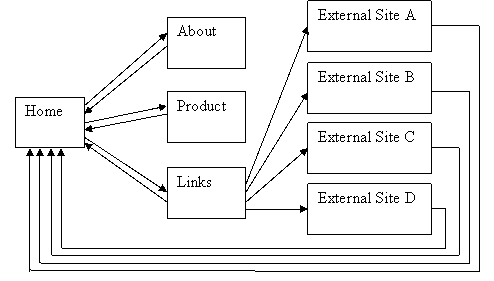

In [8]:
file="data/pagerank4.txt"

data=sc.textFile(file)
link=data.map(lambda x:(x.split(":")[0],x.split(":")[1]))
n=data.count()
print(n)
for l in link.collect():
    print(l)
rank=link.mapValues(lambda x:1.0)
for r in rank.collect():
    print(r)
t = link.join(rank)
for r in t.collect():
    print(r)
    
for i in range(5):
    rank=link.join(rank).flatMap(f).reduceByKey(lambda x,y:x+y).mapValues(lambda x:0.15+0.85*x)
    
for r in rank.collect(): 
    print(r)   

8
('Home', 'About, Product, Links')
('About', 'Home')
('Product', 'Home')
('Links', 'Home,SiteA,SiteB,SiteC,SiteD')
('SiteA', 'Home')
('SiteB', 'Home')
('SiteC', 'Home')
('SiteD', 'Home')
('Home', 1.0)
('About', 1.0)
('Product', 1.0)
('Links', 1.0)
('SiteA', 1.0)
('SiteB', 1.0)
('SiteC', 1.0)
('SiteD', 1.0)
('Home', ('About, Product, Links', 1.0))
('About', ('Home', 1.0))
('Product', ('Home', 1.0))
('SiteB', ('Home', 1.0))
('Links', ('Home,SiteA,SiteB,SiteC,SiteD', 1.0))
('SiteC', ('Home', 1.0))
('SiteA', ('Home', 1.0))
('SiteD', ('Home', 1.0))
(' Product', 0.3382349398148148)
(' Links', 0.3382349398148148)
('About', 0.3382349398148148)
('Home', 0.6586950138888888)
